### Top Rows

In [418]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, HTML

def display_scroll(df, height="400px"):
    display(HTML(f"""
    <div style="max-height:{height}; overflow:auto; border:1px solid #ccc; padding:5px;">
        {df.to_html()}
    </div>
    """))
    
file_path = "results-filtered.xlsx"

df = pd.read_excel(file_path, sheet_name="kPEX")
versions="v0 v1 v2 v3 v4".split()

# df = pd.read_excel(file_path, sheet_name="UMKP+AltRB")
# versions="v0 v1 v2 v3".split()

branchings="S R P".split()

for v in versions: 
    df[f"{v}-prep"] = (df[f"{v}-S-bnb"] == "prep")
    cols = [f"{v}-{b}-ctcp" for b in branchings]
    df[f"{v}-ctcp"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )
    cols = [f"{v}-{b}-heur" for b in branchings]
    df[f"{v}-heur"] = (
        df[cols]
        .apply(pd.to_numeric, errors="coerce")  # non-numeric → NaN
        .mean(axis=1)                           # skips NaN automatically
    )    

    
def clean_dataframe(df):
    df = df.dropna(axis=1, how="all")
    df = df.copy()

    def convert_col(col):
        # replace exact matches first
        col = col.replace({"x": 1800, "prep": 0})
        
        # try numeric conversion WITHOUT destroying original values
        numeric = pd.to_numeric(col, errors="coerce")
        
        # keep original where conversion failed
        return numeric.where(~numeric.isna(), col)

    return df.apply(convert_col)

df = clean_dataframe(df)

for v in versions: 
    df[f"{v}-init"] = df[f"{v}-heur"]+df[f"{v}-ctcp"]
    df[f"{v}-prep"] = df[f"{v}-prep"].replace(False, "")
    
df.head()
pd.set_option('display.float_format', '{:.1f}'.format)
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)

/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/2379099581.py:45: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/2379099581.py:45: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  col = col.replace({"x": 1800, "prep": 0})
/var/folders/fg/pzhds6gn509_r3cmd5yf1hnm0000gq/T/ipykernel_38912/2379099581.py:45: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To reta

In [419]:
# for v in versions: 
cols = [f"v0-{b}-mkp" for b in "S R P".split() ]
cols = [f"v{i}-{b}-mkp" for i in [0, 1] for b in "S".split() ]

mask = df[cols].apply(lambda row: row[row != 1800].nunique() > 1, axis=1)
display_scroll(df.loc[mask, cols+["dataset", "k", "v0-S-total", "v1-S-total"]])
filtered_df = df[mask]

filtered_df[["dataset", "k"]].to_excel("filtered_rows.xlsx", index=False)
mask.sum()

,v0-S-mkp,v1-S-mkp,dataset,k,v0-S-total,v1-S-total


np.int64(0)

### Varying Ratio Threshold


=== Threshold 1.2 Analysis ===
v0-init wins: 43
v2-init wins: 1327

--- Weaker side: v0-init ---


,dataset,k,v0-init,v2-init,speedup,v0-ctcp,v2-ctcp,v0-heur,v2-heur,v0-init,v2-init,v0-prep,v2-prep,v0-S-total,v2-S-total,v0-R-total,v2-R-total,v0-P-total,v2-P-total
4215,wikipedia-link-en13,2,267.1,320.7,1.20x,244.2,319.6,22.8,1.1,267.1,320.7,True,,267.1,241.3,262.7,459.1,271.4,262.1
874,dbpedia-link,9,25.5,31.8,1.24x,24.2,31.2,1.3,0.6,25.5,31.8,,,27.0,47.5,28.7,27.5,26.6,26.2
2985,sc-ldoor,6,18.1,44.0,2.43x,2.4,2.3,15.8,41.7,18.1,44.0,,,52.5,78.4,111.5,136.5,89.7,115.7
2984,sc-ldoor,5,14.5,35.5,2.44x,2.3,2.3,12.2,33.2,14.5,35.5,,,129.6,150.5,243.1,264.2,148.0,169.3
2983,sc-ldoor,4,11.7,27.8,2.37x,2.3,2.3,9.4,25.5,11.7,27.8,,,53.6,69.8,60.9,76.8,90.4,106.5
2982,sc-ldoor,3,11.1,20.0,1.80x,2.3,2.4,8.8,17.6,11.1,20.0,,,32.6,41.5,33.3,42.1,32.3,41.2
2981,sc-ldoor,2,10.1,12.3,1.22x,2.4,2.4,7.7,9.9,10.1,12.3,,,24.4,26.5,24.3,26.5,24.4,26.7
2995,sc-msdoor,6,8.1,10.6,1.32x,1.3,1.1,6.8,9.5,8.1,10.6,,,25.3,28.3,62.5,65.1,47.8,49.4
2994,sc-msdoor,5,6.5,8.6,1.32x,1.1,1.1,5.4,7.5,6.5,8.6,,,69.0,71.0,127.0,128.6,72.2,75.0
2993,sc-msdoor,4,5.8,7.0,1.21x,1.3,1.1,4.5,5.9,5.8,7.0,,,27.8,28.4,32.6,31.7,45.3,46.8



--- Stronger side: v2-init ---


,dataset,k,v0-init,v2-init,speedup,v0-ctcp,v2-ctcp,v0-heur,v2-heur,v0-init,v2-init,v0-prep,v2-prep,v0-S-total,v2-S-total,v0-R-total,v2-R-total,v0-P-total,v2-P-total
4217,wikipedia-link-en13,4,481.5,306.4,1.57x,365.1,304.9,116.4,1.5,481.5,306.4,True,,606.5,309.5,427.7,300.3,410.3,309.7
4172,web-wikipedia_link_en13-a...,4,417.5,303.6,1.38x,306.3,302.1,111.2,1.5,417.5,303.6,True,,414.0,296.6,420.5,305.7,418.2,308.8
4216,wikipedia-link-en13,3,317.6,253.0,1.26x,258.1,252.1,59.5,1.0,317.6,253.0,True,,312.8,255.6,326.1,250.1,313.9,253.7
4171,web-wikipedia_link_en13-a...,3,314.8,251.5,1.25x,255.6,250.6,59.2,1.0,314.8,251.5,True,,317.0,252.3,314.1,251.0,313.3,251.6
3484,soc-livejournal-user-grou...,7,272.8,214.5,1.27x,191.3,189.1,81.5,25.4,272.8,214.5,,,351.1,389.1,351.2,384.3,356.6,383.9
1962,livejournal-groupmembersh...,7,274.6,212.7,1.29x,192.4,187.3,82.3,25.3,274.6,212.7,,,362.8,383.3,349.3,384.7,358.9,382.0
1963,livejournal-groupmembersh...,8,131.2,94.5,1.39x,94.4,92.8,36.8,1.7,131.2,94.5,,,197.9,1792.8,204.0,1800.0,199.6,1796.2
3560,soc-sinaweibo,3,105.1,86.5,1.22x,80.9,80.6,24.2,5.9,105.1,86.5,,,393.0,556.3,1800.0,1800.0,257.5,256.8
3559,soc-sinaweibo,2,106.0,86.3,1.23x,79.2,80.6,26.8,5.7,106.0,86.3,,,153.6,165.0,1800.0,1800.0,160.7,147.7
3561,soc-sinaweibo,4,118.6,86.3,1.38x,85.9,79.9,32.8,6.3,118.6,86.3,,,1102.2,1800.0,1800.0,1800.0,358.9,607.4


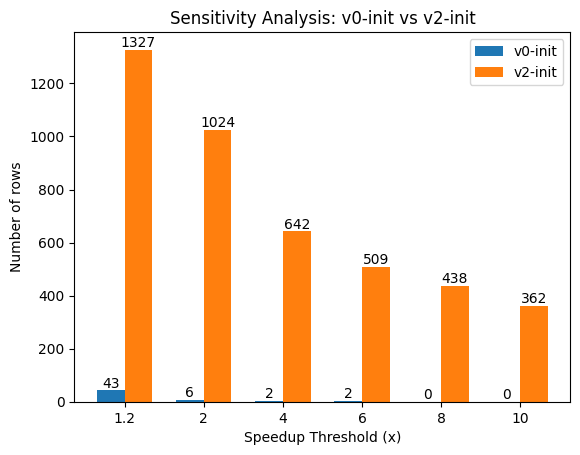

In [421]:
# =========================
# CONFIG
# =========================

col_a = "v0-init"
col_b = "v2-init"
va = col_a.split("-")[0]
vb = col_b.split("-")[0]
thresholds = [1.2, 2, 4, 6, 8, 10]
min_time_threshold = 1.0

# =========================
# Handle zeros
# =========================
df = df.replace(0, 0.01)

# =========================
# Filter
# =========================
df_filtered = df[
    (df[col_a] >= min_time_threshold) | (df[col_b] >= min_time_threshold)
].copy()

# =========================
# Compute speedups
# =========================
df_filtered["speedup_a"] = df_filtered[col_b] / df_filtered[col_a]
df_filtered["speedup_b"] = df_filtered[col_a] / df_filtered[col_b]

# =========================
# Threshold = 2 analysis
# =========================
threshold_check = thresholds[0]

a_wins = df_filtered[df_filtered["speedup_a"] >= threshold_check].copy()
b_wins = df_filtered[df_filtered["speedup_b"] >= threshold_check].copy()

# =========================
# Determine weaker & stronger
# =========================
if len(a_wins) < len(b_wins):
    weaker = "A"
    stronger = "B"
elif len(b_wins) < len(a_wins):
    weaker = "B"
    stronger = "A"
else:
    weaker = "Tie"
    stronger = "Tie"


# =========================
# Formatting function (SIDE-AWARE)
# =========================
max_len = 25

def format_df(df_in, side):
    if side == "A":
        speedup_series = df_in["speedup_a"].map(lambda x: f"{x:.2f}x")
        speedup_name = f"{col_b}/{col_a}"
    else:
        speedup_series = df_in["speedup_b"].map(lambda x: f"{x:.2f}x")
        speedup_name = f"{col_a}/{col_b}"

    return df_in.assign(
        dataset=df_in["dataset"].apply(
            lambda x: (str(x)[:max_len] + "...") if len(str(x)) > max_len else str(x)
        ),
        speedup=speedup_series
    )[[
        "dataset", "k",
        col_a, col_b,
        "speedup",
        f"{va}-ctcp", f"{vb}-ctcp",
        f"{va}-heur", f"{vb}-heur",
        f"{va}-init", f"{vb}-init",
        f"{va}-prep", f"{vb}-prep",
        f"{va}-S-total", f"{vb}-S-total",
        f"{va}-R-total", f"{vb}-R-total",
        f"{va}-P-total", f"{vb}-P-total"
    ]]
    # .rename(columns={"speedup": f"speedup ({speedup_name})"})

# =========================
# Print summary
# =========================
print(f"\n=== Threshold {threshold_check} Analysis ===")
print(f"{col_a} wins: {len(a_wins)}")
print(f"{col_b} wins: {len(b_wins)}")

# =========================
# Display results
# =========================
if weaker == "Tie":
    print("Both sides have equal wins.")

    print("\n--- Side A (>= threshold) ---")
    display_scroll(
        format_df(a_wins.sort_values(by=f"{col_a}", ascending=False), "A")
        # format_df(a_wins.sort_values(by="{speedup_a}", ascending=False), "A")
    )

    print("\n--- Side B (>= threshold) ---")
    display_scroll(
        format_df(b_wins.sort_values(by=f"{col_b}", ascending=False), "B")
        # format_df(a_wins.sort_values(by="{speedup_b}", ascending=False), "A")
    )

else:
    if weaker == "A":
        weaker_df = a_wins.sort_values(by=f"{col_a}", ascending=False)
        stronger_df = b_wins.sort_values(by=f"{col_b}", ascending=False)
        # weaker_df = a_wins.sort_values(by="speedup_a", ascending=False)
        # stronger_df = b_wins.sort_values(by="speedup_b", ascending=False)
        weaker_name, stronger_name = col_a, col_b

        print(f"\n--- Weaker side: {weaker_name} ---")
        display_scroll(format_df(weaker_df, "A"))

        print(f"\n--- Stronger side: {stronger_name} ---")
        display_scroll(format_df(stronger_df, "B"))

    else:
        weaker_df = b_wins.sort_values(by=f"{col_b}", ascending=False)
        stronger_df = a_wins.sort_values(by=f"{col_a}", ascending=False)
        # weaker_df = b_wins.sort_values(by="speedup_b", ascending=False)
        # stronger_df = a_wins.sort_values(by="speedup_a", ascending=False)
        weaker_name, stronger_name = col_b, col_a

        print(f"\n--- Weaker side: {weaker_name} ---")
        display_scroll(format_df(weaker_df, "B"))

        print(f"\n--- Stronger side: {stronger_name} ---")
        display_scroll(format_df(stronger_df, "A"))

# =========================
# Sensitivity analysis
# =========================
a_counts = []
b_counts = []

for t in thresholds:
    a_counts.append((df_filtered["speedup_a"] >= t).sum())
    b_counts.append((df_filtered["speedup_b"] >= t).sum())

# =========================
# Plot
# =========================
x = range(len(thresholds))
width = 0.35

plt.figure()

bars_a = plt.bar([i - width/2 for i in x], a_counts, width, label=col_a)
bars_b = plt.bar([i + width/2 for i in x], b_counts, width, label=col_b)

def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height,
            f"{int(height)}",
            ha='center',
            va='bottom'
        )

add_labels(bars_a)
add_labels(bars_b)

plt.xticks(x, thresholds)
plt.xlabel("Speedup Threshold (x)")
plt.ylabel("Number of rows")
plt.title(f"Sensitivity Analysis: {col_a} vs {col_b}")

plt.legend()
plt.show()